In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%run /content/drive/MyDrive/Spam_vs_Ham/preprocessing_spam_ham_dataset.py

In [ ]:
import sys
sys.path.insert(0, '/content/drive/MyDrive/Spam_vs_Ham')

from preprocessing_spam_ham_dataset import (fetch_spam_data,
                                     load_email,
                                     get_email_structure,
                                     structure_counter,
                                     html_to_plain,
                                     email_to_text,
                                     EmailToWordCounterTransformer,
                                     WordCounterToVectorTransformer,)

In [ ]:
ham_dir,spam_dir=fetch_spam_data("20021010_hard_ham.tar.bz2","20021010_spam.tar.bz2","hard_ham","spam")

In [ ]:
len_checker={}

In [ ]:
from collections import Counter

In [ ]:
for f in ham_dir.iterdir():
  len_checker.setdefault(len(f.name),[]).append(1)

In [ ]:
for size,counting in len_checker.items():
  print(size,":",len(counting))

37 : 250


In [ ]:
Counter(len(file.name) for file in spam_dir.iterdir())

Counter({37: 501})

In [ ]:
ham_filenames=[f for f in sorted(ham_dir.iterdir()) if len(f.name)>20]
spam_filenames=[f for f in sorted(spam_dir.iterdir()) if len(f.name)>20]

In [ ]:
len(ham_filenames),len(spam_filenames) #spam are more

(250, 501)

In [ ]:
ham_emails=[load_email(file) for file in ham_filenames]
spam_emails=[load_email(file) for file in spam_filenames]

In [ ]:
print(ham_emails[0].get_content().strip()[:200])

<html>
<head>
        <title>Cable companies cracking down on Wi-Fi</title>
</head>
<body bgcolor="#e5e5e5">
<center>
<a name="top"></a>
<!-- Logo and ad banner -->
<table cellpadding=0 cellspacing=0 


In [ ]:
print(spam_emails[1].get_content().strip()[:200])

<!DOCTYPE HTML PUBLIC "-//W3C//DTD HTML 4.0 Transitional//EN">
<HTML><HEAD>
<META content="text/html; charset=windows-1252" http-equiv=Content-Type>
<META content="MSHTML 5.00.2314.1000" name=GENERATO


In [ ]:
result_spam=structure_counter(spam_emails)

In [ ]:
for key, value in result_spam.items():
    print(key, ":", value)

text/plain : [0, 2, 3, 4, 5, 6, 7, 9, 11, 13, 15, 17, 18, 19, 20, 21, 22, 27, 28, 32, 33, 34, 35, 36, 45, 46, 48, 51, 53, 54, 57, 60, 62, 63, 66, 68, 69, 70, 71, 73, 75, 76, 77, 78, 79, 80, 82, 83, 84, 86, 88, 91, 92, 96, 100, 104, 105, 107, 109, 110, 113, 115, 117, 118, 119, 120, 123, 124, 125, 129, 134, 136, 138, 139, 145, 147, 148, 149, 151, 152, 156, 159, 160, 161, 162, 163, 165, 166, 167, 168, 171, 177, 178, 179, 182, 187, 191, 193, 194, 202, 206, 219, 227, 229, 233, 234, 235, 236, 237, 238, 239, 240, 244, 245, 246, 250, 252, 253, 255, 257, 259, 260, 263, 264, 265, 267, 268, 273, 277, 280, 282, 287, 288, 289, 290, 299, 302, 304, 311, 315, 322, 326, 327, 328, 329, 330, 334, 335, 336, 337, 338, 339, 348, 353, 354, 357, 358, 360, 365, 367, 369, 370, 371, 372, 373, 374, 378, 382, 383, 384, 388, 390, 392, 393, 397, 399, 403, 404, 405, 411, 412, 415, 420, 421, 422, 424, 426, 430, 431, 433, 434, 437, 438, 439, 440, 442, 443, 445, 449, 450, 453, 455, 456, 457, 458, 463, 469, 470, 471, 473

In [ ]:
[email.get_payload() for email in spam_emails[24].get_payload()]

['\nPGh0bWw+PGJvZHk+PGRpdiBpZD0ibWVzc2FnZUJvZHkiPjxkaXY+PGZvbnQg\nZmFjZT0iQXJpYWwiIHNpemU9IjIiPlRoaXMgbWVzc2FnZSBpcyBzZW50IHRv\nIG91ciBzdWJzY3JpYmVycyBvbmx5LiBGdXJ0aGVyIGVtYWlscyB0byB5b3Ug\nYnkgdGhlIHNlbmRlciB0aGlzIG9uZSB3aWxsIGJlIHN1c3BlbmRlZCBhdCBu\nbyBjb3N0IHRvIHlvdS4gU2NyZWVuaW5nIG9mIGFkZHJlc3NlcyBoYXMgYmVl\nbiBkb25lIHRvIHRoZSBiZXN0IG9mIG91ciBhYmlsaXR5LCB1bmZvcnR1bmF0\nZWx5IGl0IGlzIGltcG9zc2libGUgdG8gYmUgMTAwJSBhY2N1cmF0ZSwgc28g\naWYgeW91IGRpZCBub3QgYXNrIGZvciB0aGlzLCBvciB3aXNoIHRvIGJlIGV4\nY2x1ZGVkIG9mIHRoaXMgbGlzdCwgcGxlYXNlIGNsaWNrIDxhIGhyZWY9Im1h\naWx0bzpoZWFsdGgxMDVAbWFpbC5ydT9zdWJqZWN0PXJlbW92ZSIgdGFyZ2V0\nPSJuZXdfd2luIj5oZXJlPC9hPjwvZm9udD48L2Rpdj4gIDxwPjxiPjxmb250\nIGZhY2U9IkFyaWFsIj48Zm9udCBjb2xvcj0iI2ZmMDAwMCI+VEhJUyBJUyBG\nT1IgQURVTFQgTUVOIE9OTFkgISBJRiBZT1UgQVJFIE5PVCBBTiBBRFVMVCwg\nREVMRVRFIE5PVyAhDQo8cD4NCjxwIGFsaWduPSJjZW50ZXIiPjxpbWcgc3Jj\nPSJodHRwOi8vYTIyMDAudHJpcG9kLmNvbS5jby9waG90by5qcGciIHdpZHRo\nPSIzNTEiIGhlaWdodD0iMTc5Ij48L3A+DQo8L2ZvbnQ+PC9wPjxkaXY+V2Ug\nYXJl

In [ ]:
[vidyut_sandesh for vidyut_sandesh in spam_emails[266].get_payload()[1]]

['Content-Type',
 'Content-Transfer-Encoding',
 'Content-Disposition',
 'Content-Length']

In [ ]:
print( spam_emails[125])

Return-Path: <viagra_medication1182@martyrs.com.au>
Delivered-To: zzzz@localhost.example.com
Received: from localhost (localhost [127.0.0.1])
	by phobos.labs.example.com (Postfix) with ESMTP id 5792E43F99
	for <zzzz@localhost>; Tue, 27 Aug 2002 06:17:18 -0400 (EDT)
Received: from mail.webnote.net [193.120.211.219]
	by localhost with POP3 (fetchmail-5.9.0)
	for zzzz@localhost (single-drop); Tue, 27 Aug 2002 11:17:18 +0100 (IST)
Received: from mail.wellmode.com.tw (61-222-189-226.HINET-IP.hinet.net
 [61.222.189.226])	by webnote.net (8.9.3/8.9.3) with ESMTP id LAA30842	for
 <zzzz@example.com>; Tue, 27 Aug 2002 11:18:55 +0100
From: viagra_medication1182@martyrs.com.au
Received: from movie.netnest.com.cn (195.62.199.5 [195.62.199.5]) by
 mail.wellmode.com.tw with SMTP (Microsoft Exchange Internet Mail Service
 Version 5.5.2650.21)	id R4QN4SGP; Mon, 26 Aug 2002 12:20:54 +0800
Message-ID: <000076d12c96$00006de0$00004505@spiritairlines.com.au>
To: <samalderline223@kfta.or.kr>
Subject:
 Online 

In [ ]:
result_ham=structure_counter(ham_emails)

In [ ]:
for key,values in result_ham.items():
  print(key,':',values) #no pgp signature unlike easy ham.

text/html : [0, 1, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 40, 42, 43, 44, 45, 46, 47, 48, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 65, 66, 67, 68, 69, 70, 71, 72, 73, 76, 77, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 92, 93, 94, 95, 96, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 115, 117, 118, 121, 122, 124, 125, 126, 127, 129, 130, 136, 165, 180, 185, 188, 189, 191, 193, 209, 219, 220, 231, 232]
text/plain : [2, 3, 19, 38, 52, 64, 74, 75, 90, 91, 111, 120, 128, 131, 133, 134, 135, 138, 140, 142, 146, 147, 148, 149, 153, 154, 157, 158, 160, 163, 164, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 183, 184, 186, 187, 194, 195, 196, 197, 198, 202, 204, 205, 206, 208, 210, 211, 212, 214, 215, 216, 217, 218, 221, 222, 223, 225, 227, 228, 230, 233, 234, 235, 237, 239, 240, 242, 244, 245, 246, 247, 248, 249]
multipart(text/plain,text/html) : [6, 21, 25

In [ ]:
for sandesh in ham_emails[6].get_payload():
  print(sandesh)
  break

Content-Type: text/plain; charset=ISO-8859-1
Content-Transfer-Encoding: 7bit

E-mail error

You're subscribed to the HTML version of the Daily Dilbert,
which shows the comic strip as a graphic, but your mail system
either can't support HTML or is set up to remove HTML content. For
more information, contact your Internet service provider or mail
system administrator.

To change to a plain text subscription, modify your account
preferences at 
http://www.dilbert.com/comics/dilbert/daily_dilbert/html/login.html

The plain text option appears toward the bottom of the modification
page.







In [ ]:
print(ham_emails[13]) #URL links in ham emails are on rise!

Return-Path: <Online#3.19685.54-2t7_gc22RoTI4sRR.1.b@newsletter.online.com>
Received: from abv-sfo-acmta2.cnet.com (abv-sfo1-acmta2.cnet.com
 [206.16.1.161])	by dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id
 g6AKHYJ02058	for <qqqqqqqqqq-cnet-newsletters@example.com>; Wed, 10 Jul 2002
 21:17:34 +0100
Received: from abv-sfo1-ac-agent4 (206.16.0.226) by abv-sfo-acmta2.cnet.com
 (PowerMTA(TM) v1.5); Wed, 10 Jul 2002 16:19:34 -0700 (envelope-from
 <Online#3.19685.54-2t7_gc22RoTI4sRR.1.b@newsletter.online.com>)
Message-ID: <1219134.1026332248132.JavaMail.root@abv-sfo1-ac-agent4>
Date: Wed, 10 Jul 2002 13:17:28 -0700 (PDT)
From: CNET Shopper Electronics Edition
 <Online#3.19685.54-2t7_gc22RoTI4sRR.1@newsletter.online.com>
To: qqqqqqqqqq-cnet-newsletters@example.com
Subject:
 Looking for the perfect camera for your summer vacation? (CNET SHOPPER)
Mime-Version: 1.0
Content-Type: text/html; charset=ISO-8859-1
Content-Transfer-Encoding: 7bit
X-Mailer: Accucast (http://www.accucast.com)
X-Mail

In [ ]:
counter_spam={key:len(values) for key,values in result_spam.items()}
for key, value in counter_spam.items():
  print(key,":",value)

text/plain : 222
text/html : 181
multipart(text/plain,application/octet-stream) : 1
multipart(text/html) : 19
multipart(text/plain,text/html) : 45
multipart(text/plain) : 19
multipart(text/html,text/plain) : 1
multipart(text/html,application/octet-stream) : 2
multipart(multipart(text/html)) : 5
multipart(text/plain,image/jpeg) : 3
multipart(multipart(text/html),application/octet-stream,image/jpeg) : 1
multipart(multipart(text/plain,text/html),image/gif) : 1
multipart/alternative : 1


In [ ]:
counter_ham={key:len(values) for key,values in result_ham.items()}
for key, value in counter_ham.items():
  print(key,":",value)

text/html : 120
text/plain : 86
multipart(text/plain,text/html) : 38
multipart(text/plain,image/png,image/png) : 1
multipart(multipart(text/plain,text/html)) : 1
multipart(text/plain,application/x-pkcs7-signature) : 1
multipart(text/plain,image/bmp) : 1
multipart(text/html) : 2


In [ ]:
for header, value in spam_emails[100].items():
  print(header,':',value)

Return-Path : <guyhaibo@yahoo.ca>
Delivered-To : zzzz@localhost.example.com
Received : from localhost (localhost [127.0.0.1])	by phobos.labs.example.com (Postfix) with ESMTP id 1261547CCC	for <zzzz@localhost>; Mon, 26 Aug 2002 10:42:19 -0400 (EDT)
Received : from phobos [127.0.0.1]	by localhost with IMAP (fetchmail-5.9.0)	for zzzz@localhost (single-drop); Mon, 26 Aug 2002 15:42:19 +0100 (IST)
Received : from yahoo.ca (2.c214.ethome.net.tw [202.178.214.2]) by    dogma.slashnull.org (8.11.6/8.11.6) with SMTP id g7QDcOZ23227 for    <webmaster@efi.ie>; Mon, 26 Aug 2002 14:38:25 +0100
Received : from 157.111.91.87 ([157.111.91.87]) by mta6.snfc21.pbi.net with    asmtp; Mon, 26 Aug 2002 19:38:20 -0600
Received : from n9.groups.yahoo.com ([126.115.54.2]) by    asy100.as122.sol.superonline.com with esmtp; 26 Aug 2002 02:37:57 +1100
Received : from unknown (49.250.117.159) by smtp-server6.tampabay.rr.com    with smtp; Mon, 26 Aug 2002 15:37:34 -0200
Reply-To : guyhaibo@yahoo.ca
Message-Id : <02

In [ ]:
spam_emails[100]['Subject']

'Want to play poker with other people online.'

In [ ]:
spam_emails[0].get_content_type()

'text/plain'

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
X=np.array(ham_emails+spam_emails,dtype=object)
y=np.array([0]*len(ham_emails)+[1]*len(spam_emails))

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [ ]:
html_spam_emails=[email for email in X_train[y_train==1] if get_email_structure(email)=='text/html']

In [ ]:
sample_email=html_spam_emails[70]
print(sample_email.get_content())


<HTML><HEAD><TITLE></TITLE></HEAD><BODY BGCOLOR="WHITE">
<TABLE WIDTH=550><TR><TD><FONT SIZE=4 FACE="VERDANA" COLOR="#333366">

Have tax problems? Do you owe the IRS money? If your debt is
$5,000 US or more, we can help! Our licensed agents can help
you with both past and present tax debt. We have direct contacts
with the IRS, so once your application is processed we can help
you immediately without further delay.<BR><BR>

Also, as our client we can offer you other services and help with
other problems. Our nationally recognized tax attorneys,
paralegals, legal assistants and licensed enrolled agents can
help you with:<BR><BR>

- Tax Preparation<BR>
- Audits<BR>
- Seizures<BR>
- Bank Levies<BR>
- Asset Protection<BR>
- Audit Reconsideration<BR>
- Trust Fund Penalty Defense<BR>
- Penalty Appeals<BR>
- Penalty Abatement<BR>
- Wage Garnishments<BR>
.. and more!<BR><BR>

To receive FREE information on tax help, please fill out the
form below and return it to us. There are no obligations, 

In [ ]:
print(html_to_plain(sample_email.get_content()))


Have tax problems? Do you owe the IRS money? If your debt is
$5,000 US or more, we can help! Our licensed agents can help
you with both past and present tax debt. We have direct contacts
with the IRS, so once your application is processed we can help
you immediately without further delay.
Also, as our client we can offer you other services and help with
other problems. Our nationally recognized tax attorneys,
paralegals, legal assistants and licensed enrolled agents can
help you with:
- Tax Preparation
- Audits
- Seizures
- Bank Levies
- Asset Protection
- Audit Reconsideration
- Trust Fund Penalty Defense
- Penalty Appeals
- Penalty Abatement
- Wage Garnishments
.. and more!
To receive FREE information on tax help, please fill out the
form below and return it to us. There are no obligations, and
supplied information is kept strictly confidential. Please note
that this offer only applies to US citizens. Application
processing may take up to 10 business days.
Note: For debt size please

In [ ]:
print(email_to_text(sample_email)[:100])


Have tax problems? Do you owe the IRS money? If your debt is
$5,000 US or more, we can help! Our li


In [ ]:
import urlextract
url_extractor=urlextract.URLExtract()

In [ ]:
X_few=X_train[:4]
X_few_transformed=EmailToWordCounterTransformer().fit_transform(X_few)

In [ ]:
print(X_train[0].get_content()[:100])

Filled with useful examples and the depth, clarity, and 
attention to detail that made the first edi


In [ ]:
from scipy.sparse import csr_matrix

In [ ]:
X_few_transformed

array([Counter({'number': 14, 'the': 13, 'to': 10, 'jsp': 8, 'and': 7, 'of': 5, 'edit': 4, 'in': 4, 'with': 3, 'page': 3, 'specif': 3, 'an': 3, 'for': 3, 'as': 3, 'by': 3, 'it': 3, 'a': 3, 'order': 3, 'or': 3, 'fill': 2, 'use': 2, 'exampl': 2, 'depth': 2, 'clariti': 2, 'attent': 2, 'detail': 2, 'first': 2, 'javaserv': 2, 'numbernd': 2, 'bergsten': 2, 'is': 2, 'coverag': 2, 'tag': 2, 'librari': 2, 'thi': 2, 'url': 2, 'email': 2, 'com': 2, 'you': 2, 'newslett': 2, 'help': 2, 'that': 1, 'made': 1, 'so': 1, 'popular': 1, 'web': 1, 'develop': 1, 'just': 1, 'releas': 1, 'complet': 1, 'revis': 1, 'updat': 1, 'cover': 1, 'substanti': 1, 'chang': 1, 'version': 1, 'includ': 1, 'new': 1, 'jstl': 1, 'eagerli': 1, 'anticip': 1, 'standard': 1, 'set': 1, 'element': 1, 'task': 1, 'need': 1, 'most': 1, 'applic': 1, 'well': 1, 'thorough': 1, 'custom': 1, 'what': 1, 'peopl': 1, 'said': 1, 'about': 1, 'excel': 1, 'print': 1, 'resourc': 1, 'on': 1, 'i': 1, 'have': 1, 'been': 1, 'extrem': 1, 'impress': 1, '

In [ ]:
vocab_size=WordCounterToVectorTransformer(vocabulary_size=10)#an instance of class, this will contain necessary attributes.
RESULTS=vocab_size.fit_transform(X_few_transformed)

In [ ]:
RESULTS.toarray()#scipy.csr.matrix

array([[181,  13,  10,   7,  14,   4,   5,   1,   3,   2,   3],
       [405,  19,  13,  11,  31,  10,  14,   3,   8,   8,   9],
       [232,   9,   9,   7,   4,   3,   1,   7,   3,   4,   2],
       [ 64,   4,   4,   3,   0,   1,   1,   5,   1,   0,   0]])

In [ ]:
print(X_few[0].get_content())

Filled with useful examples and the depth, clarity, and 
attention to detail that made the first edition so popular 
with web developers, the just-released "JavaServer Pages,  
2nd Edition" (Bergsten, $44.95) is completely revised 
and updated to cover the substantial changes in the 
1.2 version of the JSP specifications, and includes 
coverage of the new JSTL Tag libraries--an eagerly 
anticipated standard  set of JSP elements for the tasks  
needed in most JSP  applications, as well as thorough 
coverage of Custom Tag Libraries.  

What people said about the first edition:

"an excellent printed resource on JSPs...I have 
been extremely impressed by its depth, clarity,
 and attention to detail. " 
--Reuven M. Lerner, Linux Journal

"This is a great book: it was written by a key 
contributor not only to the JSP specification, 
but also to the JSP and  Servlet reference 
implementations. Filled with useful examples,
 it stands as an important text in the adoption of 
JSP in the market.

In [ ]:
vocab_size.vocabulary_

{'the': 1,
 'to': 2,
 'and': 3,
 'number': 4,
 'in': 5,
 'of': 6,
 'your': 7,
 'a': 8,
 'thi': 9,
 'or': 10}

In [ ]:
vocab_size.count_of_words

[('the', 33),
 ('to', 33),
 ('and', 27),
 ('number', 24),
 ('in', 18),
 ('of', 17),
 ('your', 16),
 ('a', 15),
 ('thi', 14),
 ('or', 14)]

In [ ]:
X_100=X_train[-100:]
X_100_transformed=EmailToWordCounterTransformer().fit_transform(X_100)

In [ ]:
vocab_size=WordCounterToVectorTransformer(vocabulary_size=15)
X_100_vector=vocab_size.fit_transform(X_100_transformed)

In [ ]:
X_100_vector.toarray()[:10].tolist()

[[1406, 49, 52, 91, 32, 16, 37, 38, 25, 32, 13, 15, 10, 16, 20, 10],
 [535, 7, 31, 23, 13, 36, 11, 11, 5, 7, 6, 4, 6, 6, 3, 7],
 [218, 12, 8, 10, 6, 9, 7, 9, 6, 1, 2, 3, 6, 4, 2, 1],
 [79, 4, 5, 6, 2, 2, 2, 4, 3, 1, 1, 4, 4, 0, 1, 0],
 [718, 15, 22, 34, 20, 6, 17, 13, 13, 9, 5, 11, 1, 11, 5, 5],
 [464, 46, 21, 24, 18, 23, 5, 12, 7, 7, 5, 9, 13, 3, 2, 3],
 [172, 24, 9, 4, 5, 2, 2, 2, 3, 3, 1, 3, 4, 0, 3, 1],
 [232, 10, 7, 17, 11, 10, 7, 6, 4, 3, 4, 3, 0, 3, 0, 2],
 [41, 6, 0, 0, 0, 0, 2, 0, 2, 0, 0, 1, 0, 0, 0, 0],
 [65, 4, 0, 1, 0, 4, 0, 4, 0, 1, 1, 0, 0, 0, 0, 0]]

In [ ]:
print(url_extractor.find_urls(X_train[-97].get_content()))

['http://global.zenmarketing.net/c/images/slim/a.jpg', 'http://global.zenmarketing.net/c/images/slim/b.jpg', 'http://global.zenmarketing.net/c/images/slim/c.jpg', 'http://global.zenmarketing.net/c/images/slim/d.jpg', 'http://global.zenmarketing.net/c/images/slim/e.jpg', 'http://global.zenmarketing.net/s_link.php?nURL=http://www.slimfactors.net&email=zzzz@example.com', 'http://global.zenmarketing.net/s_link.php?nURL=http://immunetree.com/showprod.php?ID=6&email=zzzz@example.com', 'http://global.zenmarketing.net/c/images/slim/f.jpg', 'http://global.zenmarketing.net/unsub.php?email=zzzz@example.com&name=Friend']


In [ ]:
vocab_size.count_of_words

[('number', 680),
 ('to', 646),
 ('the', 637),
 ('and', 555),
 ('you', 544),
 ('a', 533),
 ('of', 504),
 ('for', 474),
 ('in', 439),
 ('your', 414),
 ('is', 384),
 ('thi', 376),
 ('on', 342),
 ('with', 334),
 ('that', 324)]

In [ ]:
print(vocab_size.vocabulary_)

{'number': 1, 'to': 2, 'the': 3, 'and': 4, 'you': 5, 'a': 6, 'of': 7, 'for': 8, 'in': 9, 'your': 10, 'is': 11, 'thi': 12, 'on': 13, 'with': 14, 'that': 15}


In [ ]:
from sklearn.pipeline import Pipeline,make_pipeline

In [ ]:
preprocess_pipeline=Pipeline([
    ("email_to_word_count",EmailToWordCounterTransformer()),
    ("word_count_to_vector",WordCounterToVectorTransformer())
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [ ]:
log_clf=LogisticRegression(max_iter=1000,random_state=42)
log_pipeline=make_pipeline(preprocess_pipeline,log_clf)

In [ ]:
score=cross_val_score(log_pipeline,X_train,y_train,cv=3)
score.mean()

np.float64(0.955)

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay

In [ ]:
log_pipeline.fit(X_train,y_train)
y_pred=log_pipeline.predict(X_test)

In [ ]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.3%}")
print(f"Precision : {precision_score(y_test,y_pred):.3%}")
print(f"Recall : {recall_score(y_test,y_pred):.3%}")
print(f"F-1 score : {f1_score(y_test,y_pred):.3%}")
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=['Ham','Spam']))

Accuracy : 96.026%
Precision : 94.393%
Recall : 100.000%
F-1 score : 97.115%
Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.88      0.94        50
        Spam       0.94      1.00      0.97       101

    accuracy                           0.96       151
   macro avg       0.97      0.94      0.95       151
weighted avg       0.96      0.96      0.96       151



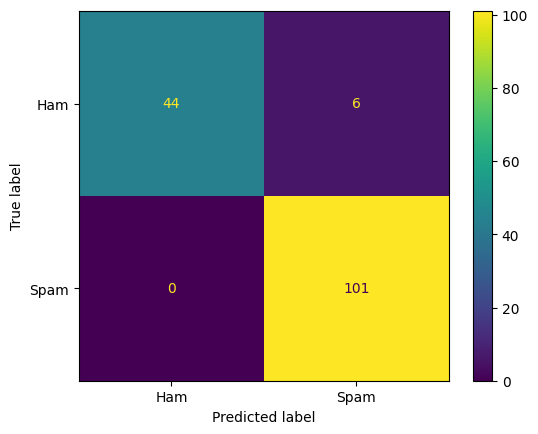

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['Ham','Spam'])
plt.show()